In [1]:
import numpy as np
#
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
#
## this next library contains some helper functions for reshaping FATES variables into easier to work with dimensions
import ctsm_py.fates_xarray_funcs as fa       
#
import textwrap
from cmcrameri import cm
import cartopy
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader
import pandas as pd
from scipy.ndimage import uniform_filter1d


ERROR 1: PROJ: proj_create_from_database: Open of /global/homes/j/jkowalcz/.conda/envs/myenv/share/proj failed


In [2]:
# make nice plots
plt.rcParams['figure.constrained_layout.use'] = True
plt.rcParams['figure.autolayout'] = False
plt.rcParams['font.size'] = 14
##plt.rcParams['text.usetex'] = True
plt.rcParams['figure.dpi'] = 300  # Set default DPI to 300 for poster figures


In [4]:
### Read in FATES file(s)
path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/SummaryFiles/'

tag1='hydro_comp_bmort_kmax_tune_sapflow_kmax3_5xHR_fixSLA_vcmax40.55_fixHR_branch'
file1=tag1+'.elm.h2.cat.nc' # should be daily output
d1 = xr.open_dataset(path+file1)


In [5]:
# Flux tower sites

## Paracou, French Guiana
par_lat=5.2787
par_lon=360.-52.9248
par_dt=-3 ## time in CSV file is local time, so we don't need to apply this to observed data

### Tapajos (TAP) - Brazil - UTC-3
tap_lat=-3.3  
tap_lon=305.0
tap_dt=-4 # solar time is UTC - 3.5
tap_dt2=-3 # flux tower data timestamp is beginning of measurement interval

## Tanguro - Brazil
tan_lat = -13.08 
tan_lon = 307.59
tan_dt = -4 # GMT-4 -- for FATES simulations
tan_dt2 = 0 ## flux tower data is in local time

## K34 -- Brazil
k34_lat = -2.6091
k34_lon = 360.-60.2093
k34_dt = -4

In [6]:
import cftime

def cftime_to_doy(cf_datetime_array):
  """
  Converts an array (or list) of cftime.DatetimeNoLeap() objects to an array of DOY values.

  Args:
    cf_datetime_array: An iterable (e.g., list, array) of cftime.DatetimeNoLeap() objects.

  Returns:
    A list of integers representing the day of year (1-365) for each input datetime object.
    Returns an empty list if the input is empty or contains non-cftime.DatetimeNoLeap objects.
  """
  doy_array = []
  for cf_datetime in cf_datetime_array:
    if isinstance(cf_datetime, cftime.DatetimeNoLeap):
      doy_array.append(cf_datetime.dayofyr)
    else:
      print(f"Warning: Skipping non-cftime.DatetimeNoLeap object: {cf_datetime}")
  return doy_array


In [7]:
fates_doy=cftime_to_doy(d1.time.values)

In [8]:
par_lat_abs_diff = np.abs(d1.lat.data - par_lat)
par_lat_ind = np.argmin(par_lat_abs_diff)
par_lon_abs_diff = np.abs(d1.lon.data - par_lon)
par_lon_ind = np.argmin(par_lon_abs_diff)

tap_lat_abs_diff = np.abs(d1.lat.data - tap_lat)
tap_lat_ind = np.argmin(tap_lat_abs_diff)
tap_lon_abs_diff = np.abs(d1.lon.data - tap_lon)
tap_lon_ind = np.argmin(tap_lon_abs_diff)

tan_lat_abs_diff = np.abs(d1.lat.data - tan_lat)
tan_lat_ind = np.argmin(tan_lat_abs_diff)
tan_lon_abs_diff = np.abs(d1.lon.data - tan_lon)
tan_lon_ind = np.argmin(tan_lon_abs_diff)

k34_lat_abs_diff = np.abs(d1.lat.data - k34_lat)
k34_lat_ind = np.argmin(k34_lat_abs_diff)
k34_lon_abs_diff = np.abs(d1.lon.data - k34_lon)
k34_lon_ind = np.argmin(k34_lon_abs_diff)

In [9]:
## seasonal cycle of stomatal conductance

fates_days=np.unique(fates_doy)

## Paracou
fates_par_avg_gs=np.zeros(len(fates_days))
fates_par_std_gs=np.zeros(len(fates_days))

## Tapajos
fates_tap_avg_gs=np.zeros(len(fates_days))
fates_tap_std_gs=np.zeros(len(fates_days))

## Tanguro
fates_tan_avg_gs=np.zeros(len(fates_days))
fates_tan_std_gs=np.zeros(len(fates_days))

## K34
fates_k34_avg_gs=np.zeros(len(fates_days))
fates_k34_std_gs=np.zeros(len(fates_days))


for i in range(len(fates_days)):
    ind=np.where(fates_doy == fates_days[i])
    fates_par_avg_gs[i]=np.nanmean((d1.FATES_STOMATAL_COND.isel(lat=par_lat_ind).isel(lon=par_lon_ind).data)[ind[0]]) 
    fates_par_std_gs[i]=np.nanstd((d1.FATES_STOMATAL_COND.isel(lat=par_lat_ind).isel(lon=par_lon_ind).data)[ind[0]]) 
    fates_tap_avg_gs[i]=np.nanmean((d1.FATES_STOMATAL_COND.isel(lat=tap_lat_ind).isel(lon=tap_lon_ind).data)[ind[0]]) 
    fates_tap_std_gs[i]=np.nanstd((d1.FATES_STOMATAL_COND.isel(lat=tap_lat_ind).isel(lon=tap_lon_ind).data)[ind[0]]) 
    fates_tan_avg_gs[i]=np.nanmean((d1.FATES_STOMATAL_COND.isel(lat=tan_lat_ind).isel(lon=tan_lon_ind).data)[ind[0]]) 
    fates_tan_std_gs[i]=np.nanstd((d1.FATES_STOMATAL_COND.isel(lat=tan_lat_ind).isel(lon=tan_lon_ind).data)[ind[0]]) 
    fates_k34_avg_gs[i]=np.nanmean((d1.FATES_STOMATAL_COND.isel(lat=k34_lat_ind).isel(lon=k34_lon_ind).data)[ind[0]]) 
    fates_k34_std_gs[i]=np.nanstd((d1.FATES_STOMATAL_COND.isel(lat=k34_lat_ind).isel(lon=k34_lon_ind).data)[ind[0]]) 
    print(i)


In [10]:
par_ymin=1*10**(-2)
par_ymax=3.3*10**(-2)

k34_ymin=1*10**(-2)
k34_ymax=3.3*10**(-2)

tap_ymin=1*10**(-2)
tap_ymax=3.3*10**(-2)

tan_ymin=1*10**(-2)
tan_ymax=3.3*10**(-2)

In [11]:
from matplotlib.patches import Rectangle
color='lightgrey'
dpm=np.max(fates_doy)/12.
gswp_par_dry=Rectangle((9*dpm,par_ymin),2*dpm,par_ymax-par_ymin, facecolor=color, alpha=0.5)
gswp_k34_dry=Rectangle((7*dpm,k34_ymin),3*dpm,k34_ymax-k34_ymin, facecolor=color, alpha=0.5)
gswp_tap_dry1=Rectangle((0*dpm,tap_ymin),1*dpm,tap_ymax-tap_ymin, facecolor=color, alpha=0.5)
gswp_tap_dry2=Rectangle((7*dpm,tap_ymin),5*dpm,tap_ymax-tap_ymin, facecolor=color, alpha=0.5)
gswp_tan_dry=Rectangle((5*dpm,tan_ymin),5*dpm,tan_ymax-tan_ymin, facecolor=color, alpha=0.5)

/tmp/ipykernel_1692534/2623957024.py:39: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


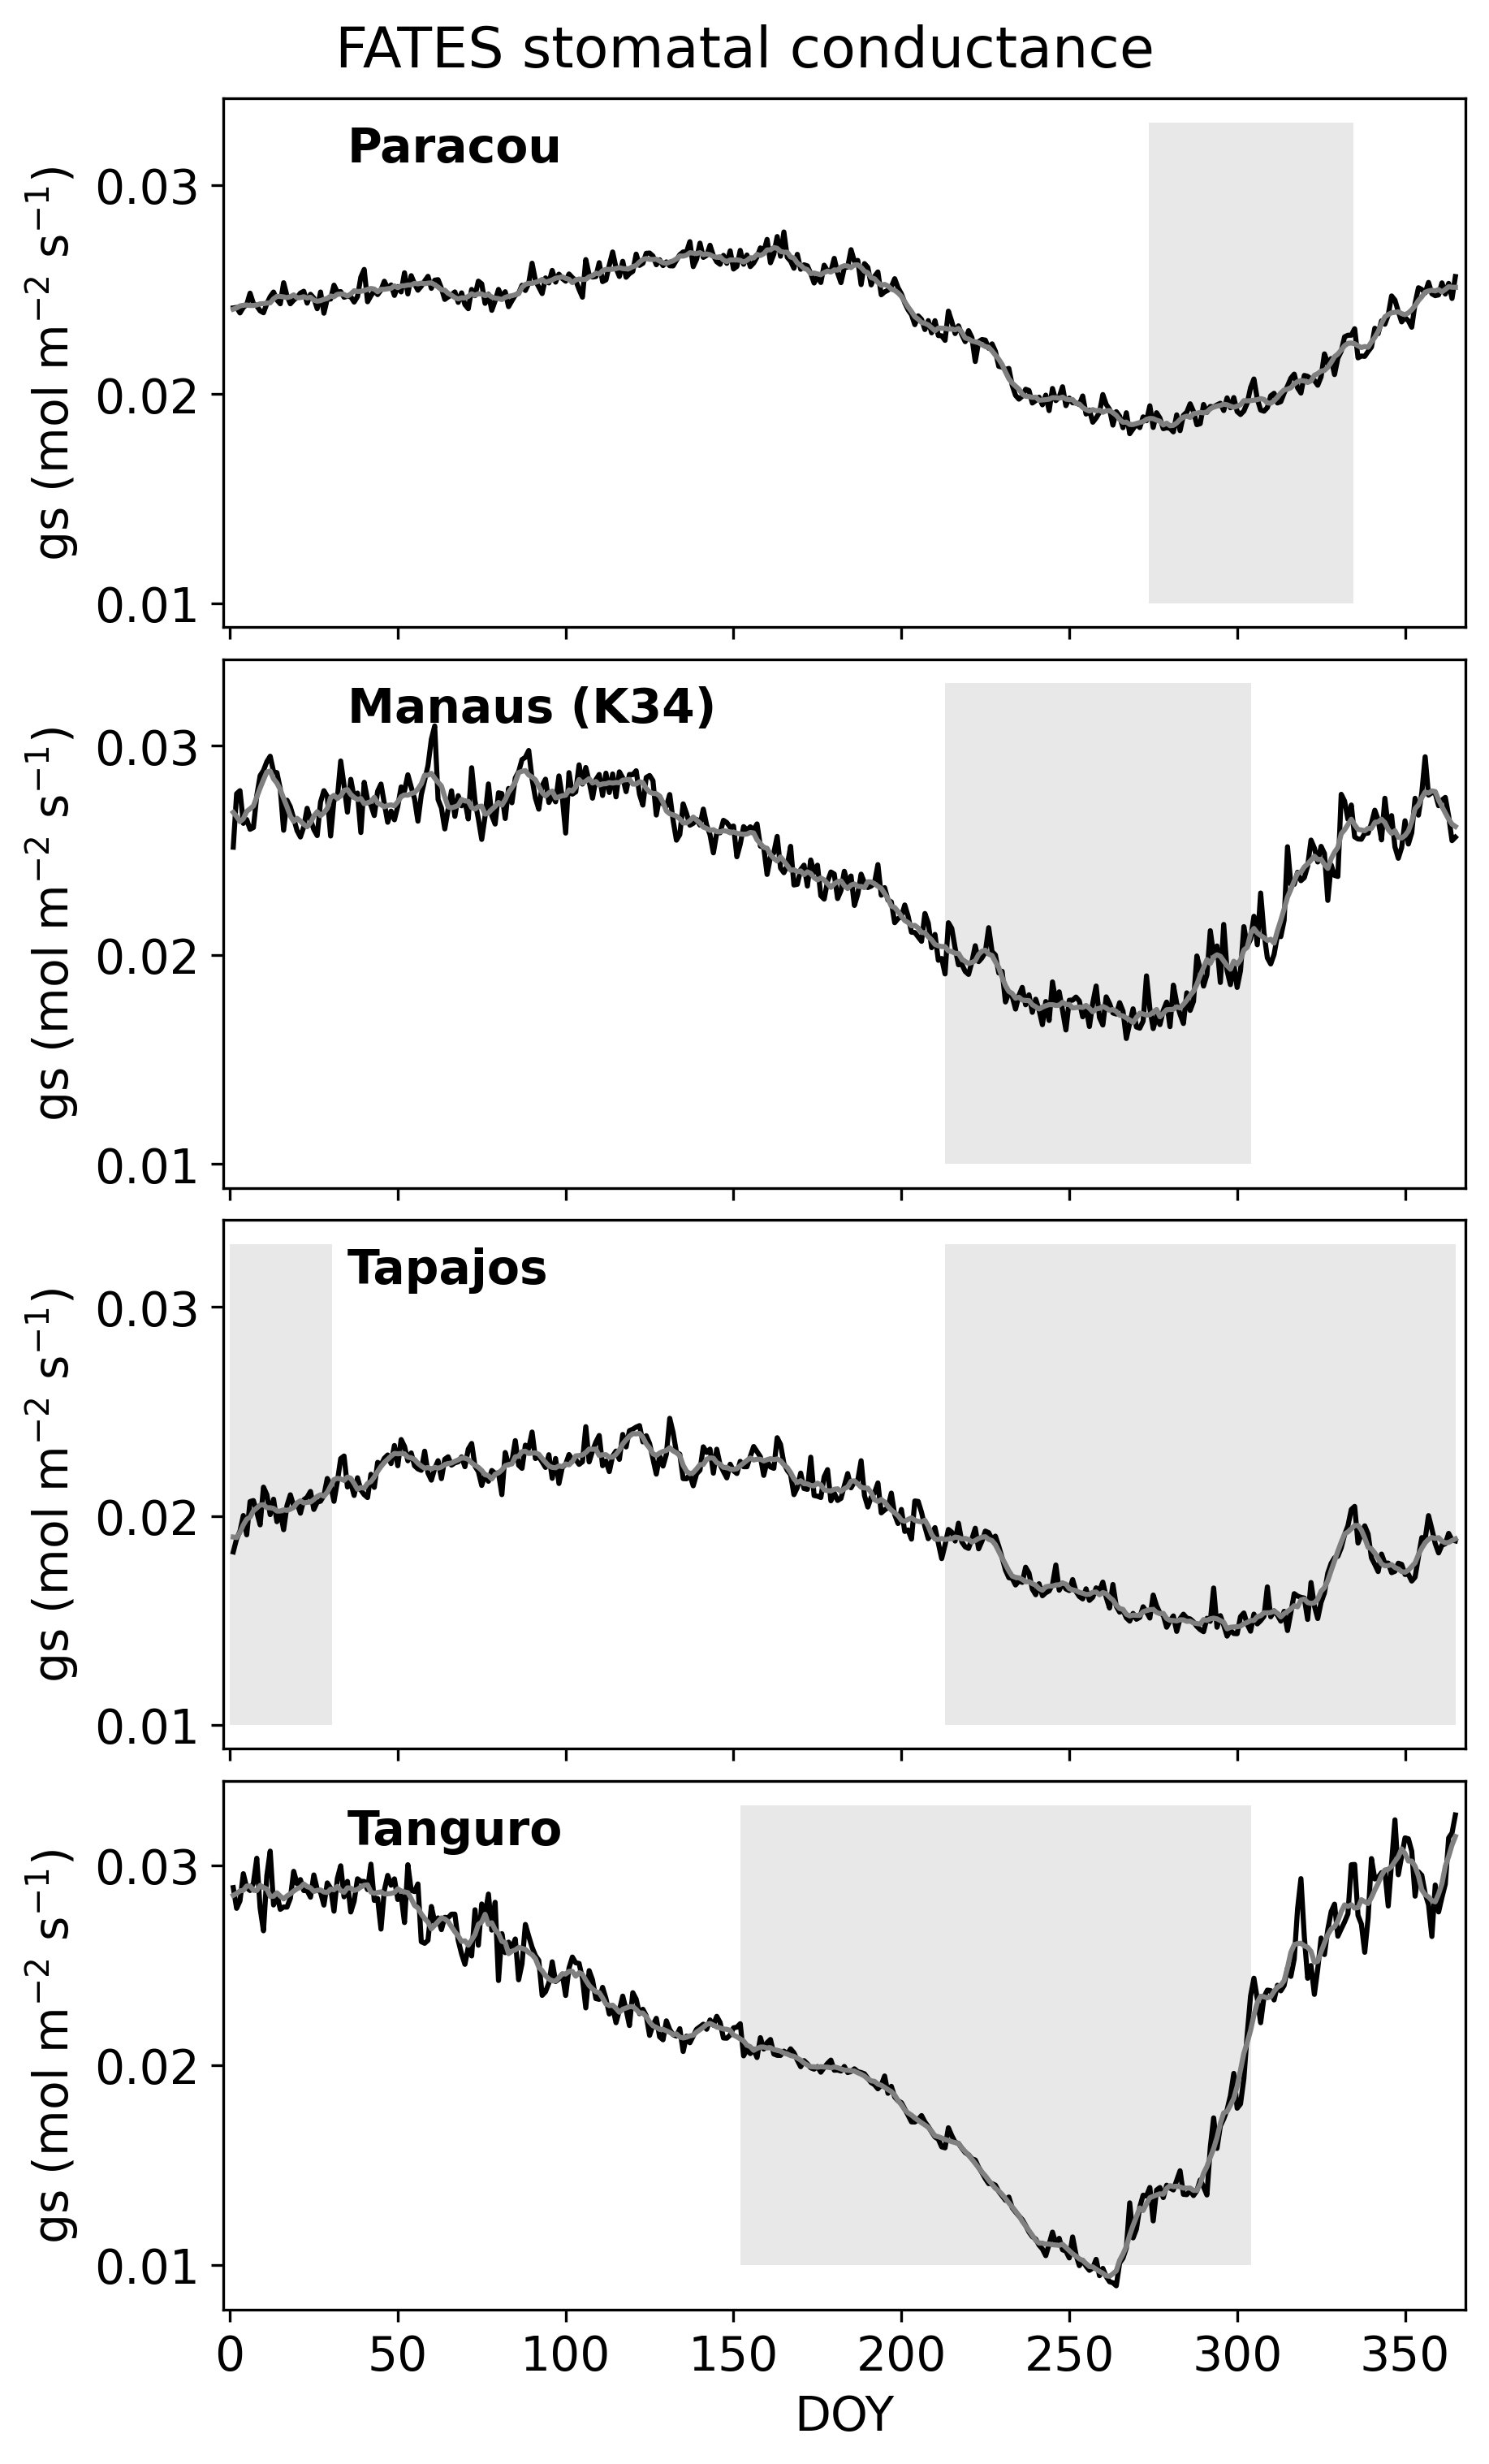

In [12]:
fig, axes = plt.subplots(4, 1, figsize=(6, 10), sharex=True)
plt.suptitle('FATES stomatal conductance')

# Panel 1 - Paracou
axes[0].add_patch(gswp_par_dry)
axes[0].plot(fates_days, fates_par_avg_gs, color="black")
axes[0].plot(fates_days, uniform_filter1d(fates_par_avg_gs, size=7), color="grey", label="gs")
axes[0].set_ylabel('gs (mol m$^{-2}$ s$^{-1}$)')
axes[0].text(0.1, 0.95, 'Paracou', transform=axes[0].transAxes, 
             fontsize=14, fontweight='bold', va='top', ha='left')
axes[0].set_xlim(-2,368)

# Panel 2 - K34 Manaus
axes[1].add_patch(gswp_k34_dry)
axes[1].plot(fates_days, fates_k34_avg_gs, color="black")
axes[1].plot(fates_days, uniform_filter1d(fates_k34_avg_gs, size=7), color="grey", label="gs")
axes[1].set_ylabel('gs (mol m$^{-2}$ s$^{-1}$)')
axes[1].text(0.1, 0.95, 'Manaus (K34)', transform=axes[1].transAxes, 
             fontsize=14, fontweight='bold', va='top', ha='left')

# Panel 3 - Tapajos
axes[2].add_patch(gswp_tap_dry1)
axes[2].add_patch(gswp_tap_dry2)
axes[2].plot(fates_days, fates_tap_avg_gs, color="black")
axes[2].plot(fates_days, uniform_filter1d(fates_tap_avg_gs, size=7), color="grey", label="gs")
axes[2].set_ylabel('gs (mol m$^{-2}$ s$^{-1}$)')
axes[2].text(0.1, 0.95, 'Tapajos', transform=axes[2].transAxes, 
             fontsize=14, fontweight='bold', va='top', ha='left')

# Panel 4 - Tanguro
axes[3].add_patch(gswp_tan_dry)
axes[3].plot(fates_days, fates_tan_avg_gs, color="black")
axes[3].plot(fates_days, uniform_filter1d(fates_tan_avg_gs, size=7), color="grey", label="gs")
axes[3].set_ylabel('gs (mol m$^{-2}$ s$^{-1}$)')
axes[3].set_xlabel('DOY')
axes[3].text(0.1, 0.95, 'Tanguro', transform=axes[3].transAxes, 
             fontsize=14, fontweight='bold', va='top', ha='left')

plt.tight_layout()
plt.show()